# TP2 : Extraction d’information

Dans ce notebook, j’analyse les textes de 1913 du corpus CAMille. Je vais extraire les mots-clés, créer un nuage de mots, repérer des entités nommées et analyser le sentiment de dix extraits.

## 1. Extraction des mots-clés

Dans cette étape, j’utilise YAKE pour repérer des expressions importantes dans les textes de 1913. Je regarderai ensuite les expressions qui reviennent le plus souvent.

In [15]:
from collections import Counter
from pathlib import Path
import yake

# Trouver le dossier du dépôt contenant data/txt
current_dir = Path.cwd()
repo_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "data" / "txt").is_dir()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError("Le dossier data/txt est introuvable.")

txt_path = repo_root / "data" / "txt"
files_1913 = sorted(txt_path.glob("*1913*.txt"))
print(f"Fichiers trouvés pour 1913 : {len(files_1913)}")

# Extraire les mots-clés avec YAKE et compter les expressions de deux mots
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
keyword_counts = Counter()

for file_path in files_1913:
    text = file_path.read_text(encoding="utf-8")
    keywords = kw_extractor.extract_keywords(text)

    bigrams = {
        keyword.lower()
        for keyword, score in keywords
        if len(keyword.split()) == 2
    }
    keyword_counts.update(bigrams)

# Afficher les 30 expressions présentes dans le plus grand nombre de fichiers
for keyword, count in keyword_counts.most_common(30):
    print(f"{keyword} : présent dans {count} fichiers")

Fichiers trouvés pour 1913 : 100
agence rossel : présent dans 32 fichiers
rue royale : présent dans 16 fichiers
rue van : présent dans 15 fichiers
rue neuve : présent dans 14 fichiers
louer maison : présent dans 8 fichiers
belle maison : présent dans 8 fichiers
bon ouvrier : présent dans 8 fichiers
louer bel : présent dans 7 fichiers
bas prix : présent dans 7 fichiers
jeune fille : présent dans 6 fichiers
hier soir : présent dans 6 fichiers
jne fille : présent dans 6 fichiers
demande bon : présent dans 6 fichiers
dem. fem : présent dans 6 fichiers
eau tombée : présent dans 5 fichiers
louer rue : présent dans 5 fichiers
dem. serv : présent dans 5 fichiers
louis xvi : présent dans 5 fichiers
dem fille : présent dans 4 fichiers
dem. bon : présent dans 4 fichiers
prix modéré : présent dans 4 fichiers
demain jeudi : présent dans 3 fichiers
rue rogler : présent dans 3 fichiers
bons gag : présent dans 3 fichiers
demain dimanche : présent dans 3 fichiers
ledit notaire : présent dans 3 fichiers

### Première observation

Les expressions qui reviennent le plus souvent semblent venir des annonces de logement et d’emploi, ainsi que des adresses. Certaines variantes, comme « jeune fille » et « jne fille », peuvent s’expliquer par des abréviations ou des erreurs d’OCR.

In [16]:
from pathlib import Path
import re
import pandas as pd
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

tb = Blobber(
    pos_tagger=PatternTagger(),
    analyzer=PatternAnalyzer()
)

## 2. Nuage de mots

Je rassemble les textes de 1913, retire des mots fréquents avec une liste de stopwords, puis crée un nuage de mots pour voir les termes qui ressortent.

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/joelmufaume/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[('BRUXELLES', 1037), ('MAISON', 822), ('PRIX', 764), ('FILLE', 629), ('PLACE', 582), ('LOUER', 561), ('HEURES', 505), ('GRAND', 481), ('VEND', 464), ('NORD', 452)]


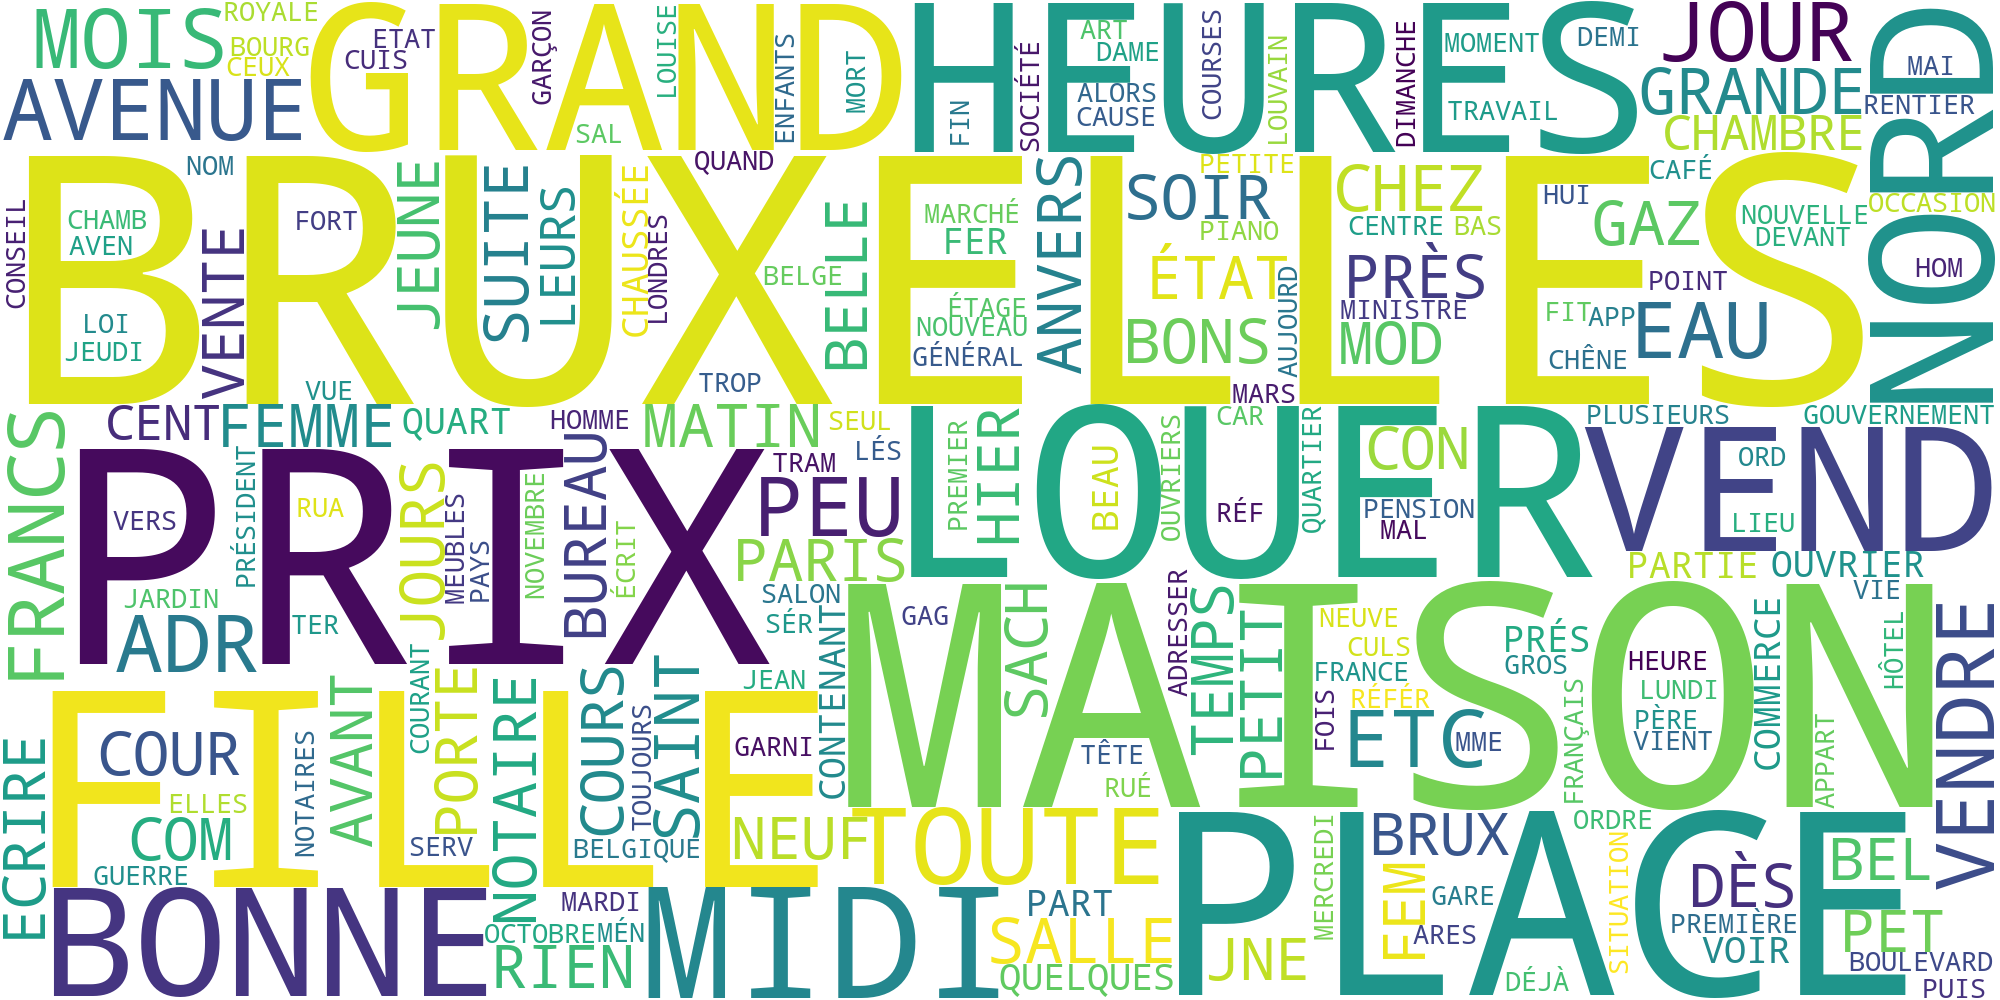

In [17]:
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from IPython.display import Image

nltk.download("stopwords")

# Liste de mots fréquents à retirer
sw = set(stopwords.words("french"))
sw.update([
    "les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
    "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
    "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
    "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
    "van", "het", "autre", "jusqu", "ville", "rossel", "dem",
    "agence", "rue", "ans", "dés", "bon", "demande", "très", "ecr"
])

# Rassembler les textes de 1913
text_1913 = " ".join(
    file_path.read_text(encoding="utf-8")
    for file_path in files_1913
)

# Retirer les mots courts, les éléments non alphabétiques et les stopwords
tokens = nltk.wordpunct_tokenize(text_1913)
clean_words = [
    word.upper()
    for word in tokens
    if len(word) > 2 and word.isalpha() and word.lower() not in sw
]

frequencies = Counter(clean_words)
print(frequencies.most_common(10))

# Créer et afficher le nuage de mots
tmp_path = repo_root / "data" / "tmp"
tmp_path.mkdir(parents=True, exist_ok=True)

image_path = tmp_path / "1913.png"
cloud = WordCloud(
    width=2000,
    height=1000,
    background_color="white"
).generate_from_frequencies(frequencies)

cloud.to_file(str(image_path))
Image(filename=str(image_path))

### Observation

Le nuage fait surtout ressortir des termes liés aux annonces de logement, de vente et d’emploi. Des mots comme « maison », « vendre », « prix » et « fille » sont très visibles. Les erreurs d’OCR et les expressions générales restent présentes malgré l’ajout de stopwords.

## 3. Reconnaissance d’entités nommées

J’utilise SpaCy pour repérer les personnes, les organisations et les lieux mentionnés dans les textes de 1913. Les erreurs d’OCR peuvent parfois être prises pour des noms.

In [18]:
from collections import defaultdict
import spacy

nlp = spacy.load("fr_core_news_md")

entities = {
    "personnes": defaultdict(int),
    "organisations": defaultdict(int),
    "lieux": defaultdict(int),
}

for file_path in files_1913:
    text = file_path.read_text(encoding="utf-8")
    doc = nlp(text)

    for ent in doc.ents:
        name = ent.text.strip()

        if len(name) <= 3:
            continue
        if ent.label_ == "PER":
            entities["personnes"][name] += 1
        elif ent.label_ == "ORG":
            entities["organisations"][name] += 1
        elif ent.label_ in ("LOC", "GPE"):
            entities["lieux"][name] += 1

for category, counts in entities.items():
    print(f"\n{category.capitalize()} :")
    for name, count in sorted(
        counts.items(),
        key=lambda item: item[1],
        reverse=True
    )[:20]:
        print(f"{name} : {count}")


Personnes :
Rossel : 412
Agence Rossel : 154
Louise : 69
culs : 54
chamb : 51
Richard : 31
Reine : 27
Ledit : 25
Gaston : 25
Arlette : 25
trav : 24
Louis XVI : 22
Poincaré : 21
Mérode : 19
Jne hom : 19
l’Empereur : 17
Jardin : 17
Albert : 17
atel : 16
jne hom : 16

Organisations :
Chambre : 51
Publicité : 34
Parlement : 20
exlg : 19
Société : 18
Couronne : 17
Conseil : 17
O n dem : 15
trav : 12
ACCOUCHEUSE : 12
Qn dem : 11
Sport : 11
Sénat : 11
UNION : 10
Agence Rossel : 10
PIANOS : 9
Times : 9
Agence : 9
OBLIQAT : 9
Bru- : 8

Lieux :
Bruxelles : 681
Anvers : 227
Nord : 174
Paris : 173
Brux : 145
Belgique : 135
Allemagne : 100
Londres : 96
Agence Rossel : 90
Gand : 88
Liège : 84
Etat : 81
Louvain : 80
Midi : 79
Ixelles : 74
France : 72
Berlin : 71
Laeken : 66
Russie : 61
Angleterre : 60


In [26]:
for category, counts in entities.items():
    print(f"\n{category.capitalize()} :")
    top_five = sorted(
        counts.items(),
        key=lambda item: item[1],
        reverse=True
    )[:5]
    for name, count in top_five:
        print(f"{name} : {count}")


Personnes :
Rossel : 412
Agence Rossel : 154
Louise : 69
culs : 54
chamb : 51

Organisations :
Chambre : 51
Publicité : 34
Parlement : 20
exlg : 19
Société : 18

Lieux :
Bruxelles : 681
Anvers : 227
Nord : 174
Paris : 173
Brux : 145


### Observation

Les lieux les plus souvent détectés sont Bruxelles, Anvers et Paris. « Brux » semble être une variante abrégée de Bruxelles, tandis que « Nord » est ambigu. Les catégories personnes et organisations sont plus difficiles à interpréter par exemple : « Rossel » et « Agence Rossel » semblent mal classés, et certains résultats comme « culs », « chamb » ou « exlg » peuvent venir d’erreurs d’OCR. c'est mieux de vérifier les entités dans leur contexte.

## 4. Analyse de sentiment

J’analyse dix extraits des textes de 1913 avec TextBlob-FR. L’outil estime leur polarité et leur subjectivité, mais les erreurs d’OCR peuvent influencer les résultats.

## Création de la fonction d’analyse

Cette fonction analyse une phrase et renvoie deux valeurs qui sont la polarité, qui indique si le texte paraît positif ou négatif, et la subjectivité, qui estime s’il exprime une opinion ou reste plutôt factuel.

In [19]:
def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    return polarity, subjectivity

## Test de la fonction

Je teste la fonction avec deux phrases simples pour vérifier qu’elle renvoie bien les valeurs de polarité et de subjectivité.

In [20]:
phrase_positive = "Ce journal est vraiment super intéressant."
phrase_negative = "Cette phrase est négative et je ne suis pas content !"

print("Phrase positive :", get_sentiment(phrase_positive))
print("Phrase négative :", get_sentiment(phrase_negative))

Phrase positive : (0.65, 0.75)
Phrase négative : (-0.40625, 0.6)


## Sélection de phrases dans les textes de 1913

Je cherche des extraits dans les fichiers de 1913. Le texte peut contenir des erreurs d’OCR ; je conserve les mots tels qu’ils apparaissent dans les fichiers.

In [21]:
import random

current_dir = Path.cwd()

repo_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "data" / "txt").is_dir()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError(
        f"Le dossier data/txt est introuvable depuis {current_dir}"
    )

txt_path = repo_root / "data" / "txt"

files_1913 = sorted(txt_path.glob("*1913*.txt"))
candidates_by_file = {}

for file_path in files_1913:
    text = file_path.read_text(encoding="utf-8")

    for sentence in re.split(r"(?<=[.!?])\s+", text):
        sentence = " ".join(sentence.split())
        if 60 <= len(sentence) <= 250:
            candidates_by_file.setdefault(file_path.name, []).append(sentence)

random.seed(42)
sampled_files = random.sample(
    list(candidates_by_file),
    min(20, len(candidates_by_file))
)

print(f"Fichiers de 1913 : {len(files_1913)}")
for file_name in sampled_files:
    print(f"{file_name} : {random.choice(candidates_by_file[file_name])}\n")

Fichiers de 1913 : 100
KB_JB838_1913-10-25_01-00006.txt : pour là camp, 'ménage sans enfant,le mari cocher-domestique, 1 cheval; la femme sachant' s’occup.

KB_JB838_1913-02-16_01-00009.txt : eéntral, électr., nettoyage par aspiration, etc., à loner 7.000 ou 5.000 fr., chauff.

KB_JB838_1913-01-16_01-00003.txt : Il est soupçonné d'être l'auteur de l’assassinat commis récemment A Ucole.

KB_JB838_1913-12-11_01-00004.txt : Si 60 45 — 68 — 99 — 43 — 635 — «9 — 227 £0 669 ôu 550 50 £4 75 45 50 62 50 44 — 510 — 121 — '230 — £60 — 669 — Bruxellois div.tOHZ— 1085 — Buenos-Avres c.126 60 129 — Bucnos-Avresd.

KB_JB838_1913-04-30_01-00008.txt : La Reine des Castagnettes I«3s fataeux artistes universels dans leur numéro de musiciens, jongleurs, imitateurs, illusionistes, acrobates aérifena et athlètes.

KB_JB838_1913-04-19_01-00008.txt : 1400 A rend.395 D^ggJdDambejroon^ao Orchestrions PIANOS et yiOtlNÀ huppelo.

KB_JB838_1913-03-30_01-00001.txt : WtBLAlC/tM L |f moi», fr..L25; 0 mok, tr.4.»; i 

In [22]:
selected_sentences = [
    {
        "fichier": "KB_JB838_1913-01-16_01-00003.txt",
        "phrase": "Il est soupçonné d'être l'auteur de l’assassinat commis récemment A Ucole."
    },
    {
        "fichier": "KB_JB838_1913-11-09_01-00003.txt",
        "phrase": "Seule, Mme Maitrepierre, venue avec des amis, reconnut son mari dont le corps est affreusement mutilé."
    },
    {
        "fichier": "KB_JB838_1913-02-05_01-00003.txt",
        "phrase": "Le contrat devra être signé par les banquiers, le premier ministre et les ministres des affaires étrangères et des finances."
    },
    {
        "fichier": "KB_JB838_1913-02-15_01-00001.txt",
        "phrase": "nous n’avons qu’à lire .les lettres touchantes quâ nous sont envoyées."
    },
    {
        "fichier": "KB_JB838_1913-10-19_01-00002.txt",
        "phrase": "Rouerd type d'excellente façon le personnage inquiétant de Raphaël."
    },
    {
        "fichier": "KB_JB838_1913-11-24_01-00003.txt",
        "phrase": "La lueur a duré quatre à cinq secondes, et a Lavaur te passage du bolide a été accompagné d’un grondement suivi d’une forte détonation."
    },
    {
        "fichier": "KB_JB838_1913-12-12_01-00010.txt",
        "phrase": "La gélatine molle, qui les cm toure se dissout instantanément dans l'estomac, oe qui assure’ un effet rapide."
    },
    {
        "fichier": "KB_JB838_1913-07-28_01-00002.txt",
        "phrase": "Cinq minutes après, installés dans son boudoir, je déroule mon fameux manuscrit."
    },
    {
        "fichier": "KB_JB838_1913-10-29_01-00002.txt",
        "phrase": "décision du Conseil.en ce qui con- ,cerne.la taxe sur les petits Jeux, a paru, le Collège s’est mis en mesure de l'appliquer."
    },
    {
        "fichier": "KB_JB838_1913-02-27_01-00005.txt",
        "phrase": "Aussi croyons- nous faire œuvre réellement utile en offrant 1 SHAHS t FRANCO] un échantillon des produits que comporte ce traitement ainsi qu’une Brochure explicative du plus haut intérêt."
    },
]

In [24]:
selected_sentences[4] = {
    "fichier": "KB_JB838_1913-12-12_01-00010.txt",
    "phrase": "Notre' vin pectoral contient suffisamment d’essence d’eucalyptus pour guérir les affections v des voies respiratoires, sans provoquer des trou-' blés oe.l’estomac."
}

selected_sentences[8] = {
    "fichier": "KB_JB838_1913-05-30_01-00002.txt",
    "phrase": "Seulement il arrive Ifàrfdfci qno le metteur en pages se trompe et, comme hier, attribué h Milite la « Chronique bruxelloise » de Christine."
}

## Analyse des dix extraits

J’applique la fonction à chaque extrait et je rassemble les valeurs obtenues dans un tableau. Les scores restent des estimations, surtout lorsque le texte contient des erreurs d’OCR.

In [25]:
results = []

for item in selected_sentences:
    polarity, subjectivity = get_sentiment(item["phrase"])
    results.append({
        "Fichier": item["fichier"],
        "Phrase": item["phrase"],
        "Polarité": round(polarity, 3),
        "Subjectivité": round(subjectivity, 3),
    })

sentiment_table = pd.DataFrame(results)
sentiment_table

,Fichier,Phrase,Polarité,Subjectivité
0,KB_JB838_1913-01-16_01-00003.txt,Il est soupçonné d'être l'auteur de l’assassin...,0.000,0.000
1,KB_JB838_1913-11-09_01-00003.txt,"Seule, Mme Maitrepierre, venue avec des amis, ...",0.325,0.475
2,KB_JB838_1913-02-05_01-00003.txt,"Le contrat devra être signé par les banquiers,...",0.150,0.250
3,KB_JB838_1913-02-15_01-00001.txt,nous n’avons qu’à lire .les lettres touchantes...,0.300,0.900
4,KB_JB838_1913-12-12_01-00010.txt,Notre' vin pectoral contient suffisamment d’es...,0.000,0.000
5,KB_JB838_1913-11-24_01-00003.txt,"La lueur a duré quatre à cinq secondes, et a L...",0.205,0.150
6,KB_JB838_1913-12-12_01-00010.txt,"La gélatine molle, qui les cm toure se dissout...",0.350,0.400
7,KB_JB838_1913-07-28_01-00002.txt,"Cinq minutes après, installés dans son boudoir...",0.100,0.400
8,KB_JB838_1913-05-30_01-00002.txt,Seulement il arrive Ifàrfdfci qno le metteur e...,-0.010,0.000
9,KB_JB838_1913-02-27_01-00005.txt,Aussi croyons- nous faire œuvre réellement uti...,0.217,0.180


### Observation

Sur les dix extraits analysés, sept ont une polarité positive, deux sont neutres et un est presque neutre. La polarité moyenne est d’environ 0,164 et la subjectivité moyenne d’environ 0,276. Certains extraits contiennent des erreurs d’OCR ; par exemple, un passage sur un assassinat est classé comme neutre. Ces résultats concernent uniquement les dix extraits choisis et ne représentent pas l’ensemble de l’année.